# LOGISTIC REGRESSION - SOLVER SAGA (L1)

### Deskripsi Teori & Varian:
* **Algoritma**: Logistic Regression (L1)
* **Varian**: Solver Saga
* **Konsep**: `saga` adalah varian algoritma optimasi (Stochastic Average Gradient) yang lebih modern dibanding `liblinear`. Solver ini sangat efisien untuk dataset berukuran besar dan mendukung semua jenis penalti (L1, L2, ElasticNet). Varian ini diuji untuk membandingkan kecepatan dan stabilitas konvergensi dibandingkan solver standar.

In [1]:
import time
import tracemalloc
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

df_hoaks = pd.read_csv('../data/komdigi_hoaks.csv')
df_valid = pd.read_csv('../web/uploads/berita_valid_terbaru.csv')

def clean_text(text):
    if not isinstance(text, str): return ''
    text = re.sub(r'\[(HOAKS|DISINFORMASI|MISINFORMASI|KLARIFIKASI|SALAH|FALSE)\]', '', text, flags=re.IGNORECASE)
    text = re.sub(r'\((HOAKS|DISINFORMASI|MISINFORMASI|KLARIFIKASI|SALAH|FALSE)\)', '', text, flags=re.IGNORECASE)
    text = re.sub(r'https?:\/\/\S+|www\.\S+', '', text)
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    return re.sub(r'\s+', ' ', text.lower()).strip()

df_hoaks['teks_bersih'] = (df_hoaks['title'].fillna('') + ' ' + df_hoaks['excerpt'].fillna('')).apply(clean_text)
df_valid['teks_bersih'] = (df_valid['title'].fillna('') + ' ' + df_valid['excerpt'].fillna('')).apply(clean_text)

df_hoaks['label'] = 1
df_valid['label'] = 0

df_hoaks_sampel = df_hoaks.sample(n=len(df_valid), random_state=42)
df_all = pd.concat([df_hoaks_sampel, df_valid], ignore_index=True)
df_all = df_all[df_all['teks_bersih'].str.len() > 10].reset_index(drop=True)

X_train, X_test, y_train, y_test = train_test_split(
    df_all['teks_bersih'], df_all['label'], test_size=0.2, random_state=42, stratify=df_all['label']
)
tfidf = TfidfVectorizer(max_features=1500, ngram_range=(1, 2))
X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)

print("Preprocessing Selesai!")

Preprocessing Selesai!


In [2]:
tracemalloc.start()
waktu_mulai = time.time()

# Model Logistic Regression L1 dengan Solver Saga
model = LogisticRegression(penalty='l1', solver='saga', C=1.0, max_iter=2000, random_state=42)
model.fit(X_train_vec, y_train)
y_pred = model.predict(X_test_vec)

waktu_eksekusi = time.time() - waktu_mulai
current_mem, peak_mem = tracemalloc.get_traced_memory()
tracemalloc.stop()
memori_mb = peak_mem / (1024 * 1024)

acc = accuracy_score(y_test, y_pred)
prec_macro = precision_score(y_test, y_pred, average='macro', zero_division=0)
rec_macro = recall_score(y_test, y_pred, average='macro', zero_division=0)
f1_macro = f1_score(y_test, y_pred, average='macro', zero_division=0)
f1_weighted = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print("=============================================")
print("HASIL PENGUJIAN: LOGISTIC REGRESSION - SOLVER SAGA (L1)")
print("=============================================")
print(f"1. Algoritma        : Logistic Regression")
print(f"2. Metrik Jarak     : L1 Regularization (Saga)")
print(f"3. Akurasi          : {acc:.4f}")
print(f"4. Precision (Macro): {prec_macro:.4f}")
print(f"5. Recall (Macro)   : {rec_macro:.4f}")
print(f"6. F1-Score (Macro) : {f1_macro:.4f}")
print(f"7. F1-Score (Weighted): {f1_weighted:.4f}")
print(f"8. Waktu Eksekusi   : {waktu_eksekusi:.4f} detik")
print(f"9. Penggunaan Memori: {memori_mb:.2f} MB")
print("=============================================\n")

print("Laporan Klasifikasi Detail:")
print(classification_report(y_test, y_pred, target_names=['Valid (0)', 'Hoaks (1)'], zero_division=0))

HASIL PENGUJIAN: LOGISTIC REGRESSION - SOLVER SAGA (L1)
1. Algoritma        : Logistic Regression
2. Metrik Jarak     : L1 Regularization (Saga)
3. Akurasi          : 0.8633
4. Precision (Macro): 0.8737
5. Recall (Macro)   : 0.8633
6. F1-Score (Macro) : 0.8624
7. F1-Score (Weighted): 0.8624
8. Waktu Eksekusi   : 0.1235 detik
9. Penggunaan Memori: 0.16 MB

Laporan Klasifikasi Detail:
              precision    recall  f1-score   support

   Valid (0)       0.81      0.95      0.87       150
   Hoaks (1)       0.94      0.78      0.85       150

    accuracy                           0.86       300
   macro avg       0.87      0.86      0.86       300
weighted avg       0.87      0.86      0.86       300



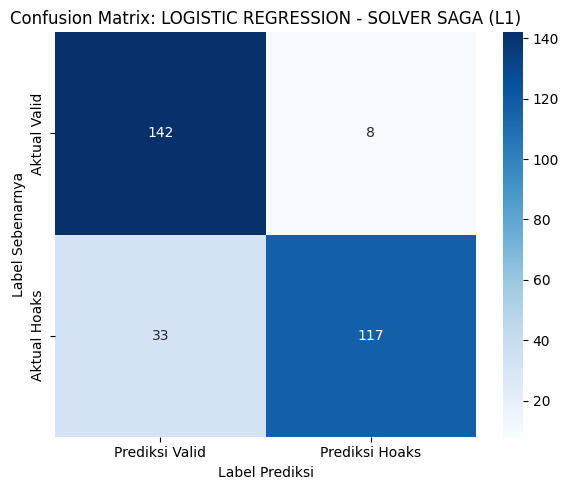

In [3]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Prediksi Valid', 'Prediksi Hoaks'],
            yticklabels=['Aktual Valid', 'Aktual Hoaks'])
plt.title('Confusion Matrix: LOGISTIC REGRESSION - SOLVER SAGA (L1)')
plt.ylabel('Label Sebenarnya')
plt.xlabel('Label Prediksi')
plt.tight_layout()
plt.show()

### Pembahasan Akademis: Logistic Regression (L1 dengan Solver Saga)

1. **Analisis Performa & Akurasi**:
   * Model dengan penalti L1 dan solver `saga` menghasilkan akurasi sebesar **86.33%** dengan F1-Score 0.8624.
   * Angka ini **persis identik** dengan hasil L1 menggunakan solver `liblinear` (86.33%). Dari Confusion Matrix, model menebak 142 Valid dan 117 Hoaks dengan benar (33 Hoaks lolos sebagai Valid). Ini membuktikan bahwa secara matematis, kedua solver ini konvergen ke titik optimal (bobot) yang sama untuk penalti L1 pada data ini.

2. **Karakteristik Solver Saga**:
   * Solver `saga` (Stochastic Average Gradient) adalah algoritma optimasi modern yang dirancang untuk data berdimensi tinggi dan berskala besar. 
   * Walaupun hasil akurasinya sama, `saga` membutuhkan waktu lebih lama (0.1235 detik) dan memori lebih besar (0.16 MB) dibanding `liblinear`. Hal ini karena `saga` menggunakan pendekatan *stochastic* (acak per sampel) yang membutuhkan iterasi lebih banyak untuk konvergen, ditambah fitur-fitur internalnya yang lebih kompleks.

3. **Kesimpulan Eksperimen**:
   * Untuk dataset TF-IDF berukuran sedang ini (sekitar 1.500 fitur), solver bawaan `liblinear` terbukti lebih efisien dan sama akuratnya dibanding `saga` untuk penalti L1.